# Customer Churn - Feature Engineering
Steps: import, load data, price features, date features, encoding, skewness, correlation

## 1. Import packages

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime

%matplotlib inline
sns.set(color_codes=True)

## 2. Load data

In [2]:
# raw client data (no missing values, so no extra cleaning needed)
df = pd.read_csv("../data/client_data.csv")
price_df = pd.read_csv("../data/price_data.csv")

# convert dates
for col in ["date_activ", "date_end", "date_modif_prod", "date_renewal"]:
    df[col] = pd.to_datetime(df[col], format="%Y-%m-%d")
price_df["price_date"] = pd.to_datetime(price_df["price_date"], format="%Y-%m-%d")

df.head(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,0,0.0,1.78,0.114481,0.098142,40.606701,t,0.0,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,0,0.0,16.27,0.145711,0.000000,44.311378,f,0.0,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,0,0.0,38.72,0.165794,0.087899,44.311378,f,0.0,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0


## 3. Price features

### Off-peak price difference: December vs January

In [3]:
# monthly off-peak price per company
monthly = price_df.groupby(["id", "price_date"]).agg(
    {"price_off_peak_var": "mean", "price_off_peak_fix": "mean"}).reset_index()

# first month (Jan) and last month (Dec) per company
jan = monthly.groupby("id").first().reset_index()
dec = monthly.groupby("id").last().reset_index()

diff = pd.merge(dec.rename(columns={"price_off_peak_var": "dec_1", "price_off_peak_fix": "dec_2"}),
                jan.drop(columns="price_date"), on="id")
diff["offpeak_diff_dec_jan_energy"] = diff["dec_1"] - diff["price_off_peak_var"]
diff["offpeak_diff_dec_jan_power"] = diff["dec_2"] - diff["price_off_peak_fix"]

df = pd.merge(df, diff[["id", "offpeak_diff_dec_jan_energy", "offpeak_diff_dec_jan_power"]], on="id")
df.head(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn,offpeak_diff_dec_jan_energy,offpeak_diff_dec_jan_power
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,0,0.0,1.78,0.114481,0.098142,40.606701,t,0.0,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1,0.020057,3.700961
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,0,0.0,16.27,0.145711,0.000000,44.311378,f,0.0,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0,-0.003767,0.177779
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,0,0.0,38.72,0.165794,0.087899,44.311378,f,0.0,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0,-0.004670,0.177779


### Average price difference between periods
More detail than the Dec-Jan feature.

In [4]:
price_cols = ["price_off_peak_var", "price_peak_var", "price_mid_peak_var",
              "price_off_peak_fix", "price_peak_fix", "price_mid_peak_fix"]

# add the 6 period differences to a price table
def add_diffs(t):
    t["off_peak_peak_var_diff"] = t["price_off_peak_var"] - t["price_peak_var"]
    t["peak_mid_peak_var_diff"] = t["price_peak_var"] - t["price_mid_peak_var"]
    t["off_peak_mid_peak_var_diff"] = t["price_off_peak_var"] - t["price_mid_peak_var"]
    t["off_peak_peak_fix_diff"] = t["price_off_peak_fix"] - t["price_peak_fix"]
    t["peak_mid_peak_fix_diff"] = t["price_peak_fix"] - t["price_mid_peak_fix"]
    t["off_peak_mid_peak_fix_diff"] = t["price_off_peak_fix"] - t["price_mid_peak_fix"]
    return t

diff_cols = ["off_peak_peak_var_diff", "peak_mid_peak_var_diff", "off_peak_mid_peak_var_diff",
             "off_peak_peak_fix_diff", "peak_mid_peak_fix_diff", "off_peak_mid_peak_fix_diff"]

# mean price per company, then differences
mean_prices = add_diffs(price_df.groupby("id")[price_cols].mean().reset_index())
mean_feats = mean_prices[["id"] + diff_cols].rename(columns={c: c.replace("_diff", "_mean_diff") for c in diff_cols})
df = pd.merge(df, mean_feats, on="id")
df.head(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn,offpeak_diff_dec_jan_energy,offpeak_diff_dec_jan_power,off_peak_peak_var_mean_diff,peak_mid_peak_var_mean_diff,off_peak_mid_peak_var_mean_diff,off_peak_peak_fix_mean_diff,peak_mid_peak_fix_mean_diff,off_peak_mid_peak_fix_mean_diff
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,0,0.0,1.78,0.114481,0.098142,40.606701,t,0.0,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1,0.020057,3.700961,0.024038,0.034219,0.058257,18.590255,7.45067,26.040925
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,0,0.0,16.27,0.145711,0.000000,44.311378,f,0.0,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0,-0.003767,0.177779,0.142485,0.007124,0.149609,44.311375,0.00000,44.311375
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,0,0.0,38.72,0.165794,0.087899,44.311378,f,0.0,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0,-0.004670,0.177779,0.082090,0.088421,0.170512,44.385450,0.00000,44.385450


Looks at price gaps between peak periods, not just across the year.

### Max monthly price difference

In [5]:
# mean price per company per month, then differences
by_month = add_diffs(price_df.groupby(["id", "price_date"])[price_cols].mean().reset_index())

# max difference per company
max_feats = by_month.groupby("id")[diff_cols].max().reset_index()
max_feats = max_feats.rename(columns={c: c.replace("_diff", "_max_monthly_diff") for c in diff_cols})
df = pd.merge(df, max_feats, on="id")
df.head(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn,offpeak_diff_dec_jan_energy,offpeak_diff_dec_jan_power,off_peak_peak_var_mean_diff,peak_mid_peak_var_mean_diff,off_peak_mid_peak_var_mean_diff,off_peak_peak_fix_mean_diff,peak_mid_peak_fix_mean_diff,off_peak_mid_peak_fix_mean_diff,off_peak_peak_var_max_monthly_diff,peak_mid_peak_var_max_monthly_diff,off_peak_mid_peak_var_max_monthly_diff,off_peak_peak_fix_max_monthly_diff,peak_mid_peak_fix_max_monthly_diff,off_peak_mid_peak_fix_max_monthly_diff
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,0,0.0,1.78,0.114481,0.098142,40.606701,t,0.0,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1,0.020057,3.700961,0.024038,0.034219,0.058257,18.590255,7.45067,26.040925,0.060550,0.085483,0.146033,44.26693,8.145775,44.26693
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,0,0.0,16.27,0.145711,0.000000,44.311378,f,0.0,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0,-0.003767,0.177779,0.142485,0.007124,0.149609,44.311375,0.00000,44.311375,0.151367,0.085483,0.151367,44.44471,0.000000,44.44471
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,0,0.0,38.72,0.165794,0.087899,44.311378,f,0.0,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0,-0.004670,0.177779,0.082090,0.088421,0.170512,44.385450,0.00000,44.385450,0.084587,0.089162,0.172468,44.44471,0.000000,44.44471


Customers may churn after a sudden large price change.

## 4. Other features

### Tenure
Years as a client.

In [6]:
df["tenure"] = (df["date_end"] - df["date_activ"]).dt.days // 365
df.groupby("tenure")["churn"].mean().sort_index(ascending=False)

tenure
13    0.095238
12    0.083333
11    0.059783
10    0.045455
9     0.012500
8     0.047244
7     0.075472
6     0.075407
5     0.091999
4     0.127473
3     0.143874
2     0.176471
Name: churn, dtype: float64

Short-tenure clients churn more.

### Dates to months
Months counted from reference date Jan 2016.

In [7]:
def convert_months(ref_date, df, column):
    # whole months between ref_date and the column date
    dates = df[column]
    months = (ref_date.year - dates.dt.year) * 12 + (ref_date.month - dates.dt.month)
    # subtract 1 if the day has not been reached yet
    months -= (ref_date.day < dates.dt.day).astype(int)
    return months

ref_date = datetime(2016, 1, 1)
df["months_activ"] = convert_months(ref_date, df, "date_activ")
df["months_to_end"] = -convert_months(ref_date, df, "date_end")  # minus = months left
df["months_modif_prod"] = convert_months(ref_date, df, "date_modif_prod")
df["months_renewal"] = convert_months(ref_date, df, "date_renewal")

# drop original dates
df = df.drop(columns=["date_activ", "date_end", "date_modif_prod", "date_renewal"])
df[["months_activ", "months_to_end", "months_modif_prod", "months_renewal"]].describe()

,months_activ,months_to_end,months_modif_prod,months_renewal
count,14606.000000,14606.000000,14606.000000,14606.000000
mean,58.588183,7.358483,35.470765,4.842188
std,19.370840,3.509648,30.263581,3.877985
min,16.000000,1.000000,-1.000000,-1.000000
25%,44.000000,4.000000,6.000000,2.000000
50%,57.000000,7.000000,30.000000,5.000000
75%,71.000000,10.000000,64.000000,8.000000
max,151.000000,18.000000,151.000000,30.000000


Long-time clients may be more loyal. Near contract end, switching is easier.

### Boolean: has_gas

In [8]:
df["has_gas"] = df["has_gas"].map({"t": 1, "f": 0})
df.groupby("has_gas")["churn"].mean() * 100

has_gas
0    10.054371
1     8.185590
Name: churn, dtype: float64

Clients with gas churn a bit less.

### Categorical: channel_sales and origin_up
One-hot encode, drop categories with fewer than 100 rows.

In [9]:
cols = ["channel_sales", "origin_up"]
min_count = 100

# category counts before encoding
counts = {c: df[c].value_counts() for c in cols}
df = pd.get_dummies(df, columns=cols, prefix=cols, dtype=int)

# drop rare categories
for c in cols:
    keep = set(counts[c][counts[c] >= min_count].index.astype(str))
    rare = [d for d in df.columns if d.startswith(c + "_") and d[len(c) + 1:] not in keep]
    df = df.drop(columns=rare)

df.shape

(14606, 47)

### Skewed numeric columns
Log transform (add 1 because of zeros).

In [10]:
skewed_cols = ["cons_12m", "cons_gas_12m", "cons_last_month", "forecast_cons_12m",
               "forecast_cons_year", "forecast_discount_energy", "forecast_meter_rent_12m",
               "forecast_price_energy_off_peak", "forecast_price_energy_peak",
               "forecast_price_pow_off_peak"]

print("Std before:")
print(df[skewed_cols].std().round(2))

df[skewed_cols] = np.log10(df[skewed_cols] + 1)

print("Std after:")
print(df[skewed_cols].std().round(2))

Std before:
cons_12m                          573465.26
cons_gas_12m                      162973.06
cons_last_month                    64364.20
forecast_cons_12m                   2387.57
forecast_cons_year                  3247.79
forecast_discount_energy               5.11
forecast_meter_rent_12m               66.17
forecast_price_energy_off_peak         0.02
forecast_price_energy_peak             0.05
forecast_price_pow_off_peak            4.49
dtype: float64
Std after:
cons_12m                          0.88
cons_gas_12m                      1.72
cons_last_month                   1.77
forecast_cons_12m                 0.68
forecast_cons_year                1.58
forecast_discount_energy          0.27
forecast_meter_rent_12m           0.57
forecast_price_energy_off_peak    0.01
forecast_price_energy_peak        0.02
forecast_price_pow_off_peak       0.13
dtype: float64


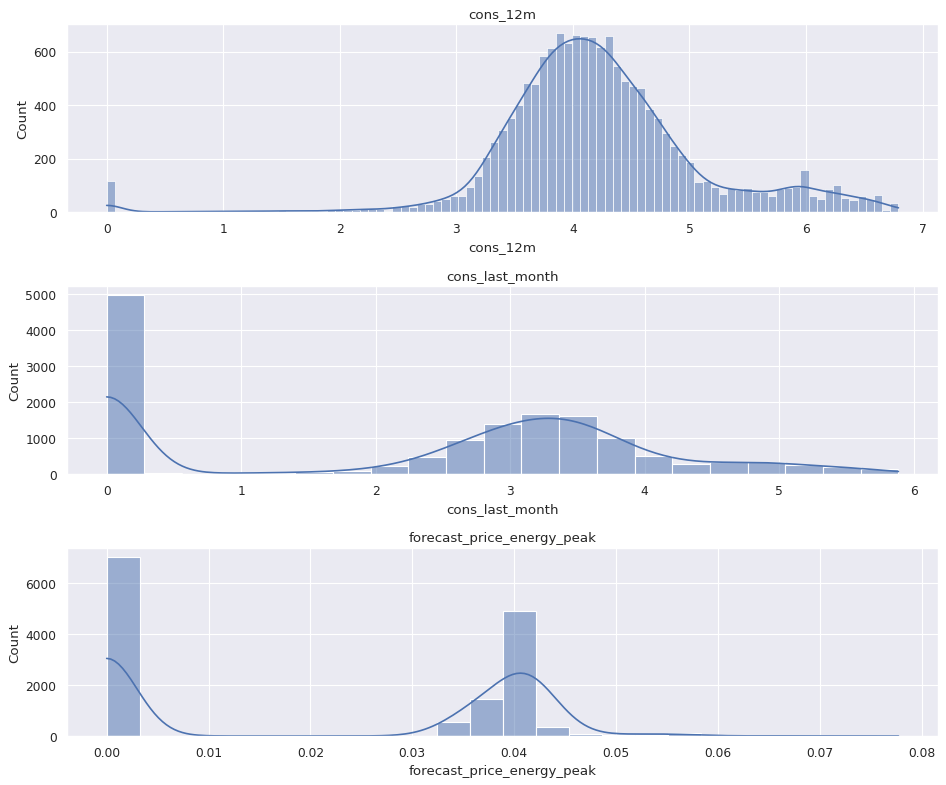

In [11]:
# check a few distributions after the transform
plot_cols = ["cons_12m", "cons_last_month", "forecast_price_energy_peak"]
fig, axs = plt.subplots(nrows=len(plot_cols), figsize=(12, 10))
for ax, col in zip(axs, plot_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()

Std drops for most columns, distributions look more normal.

## 5. Correlation

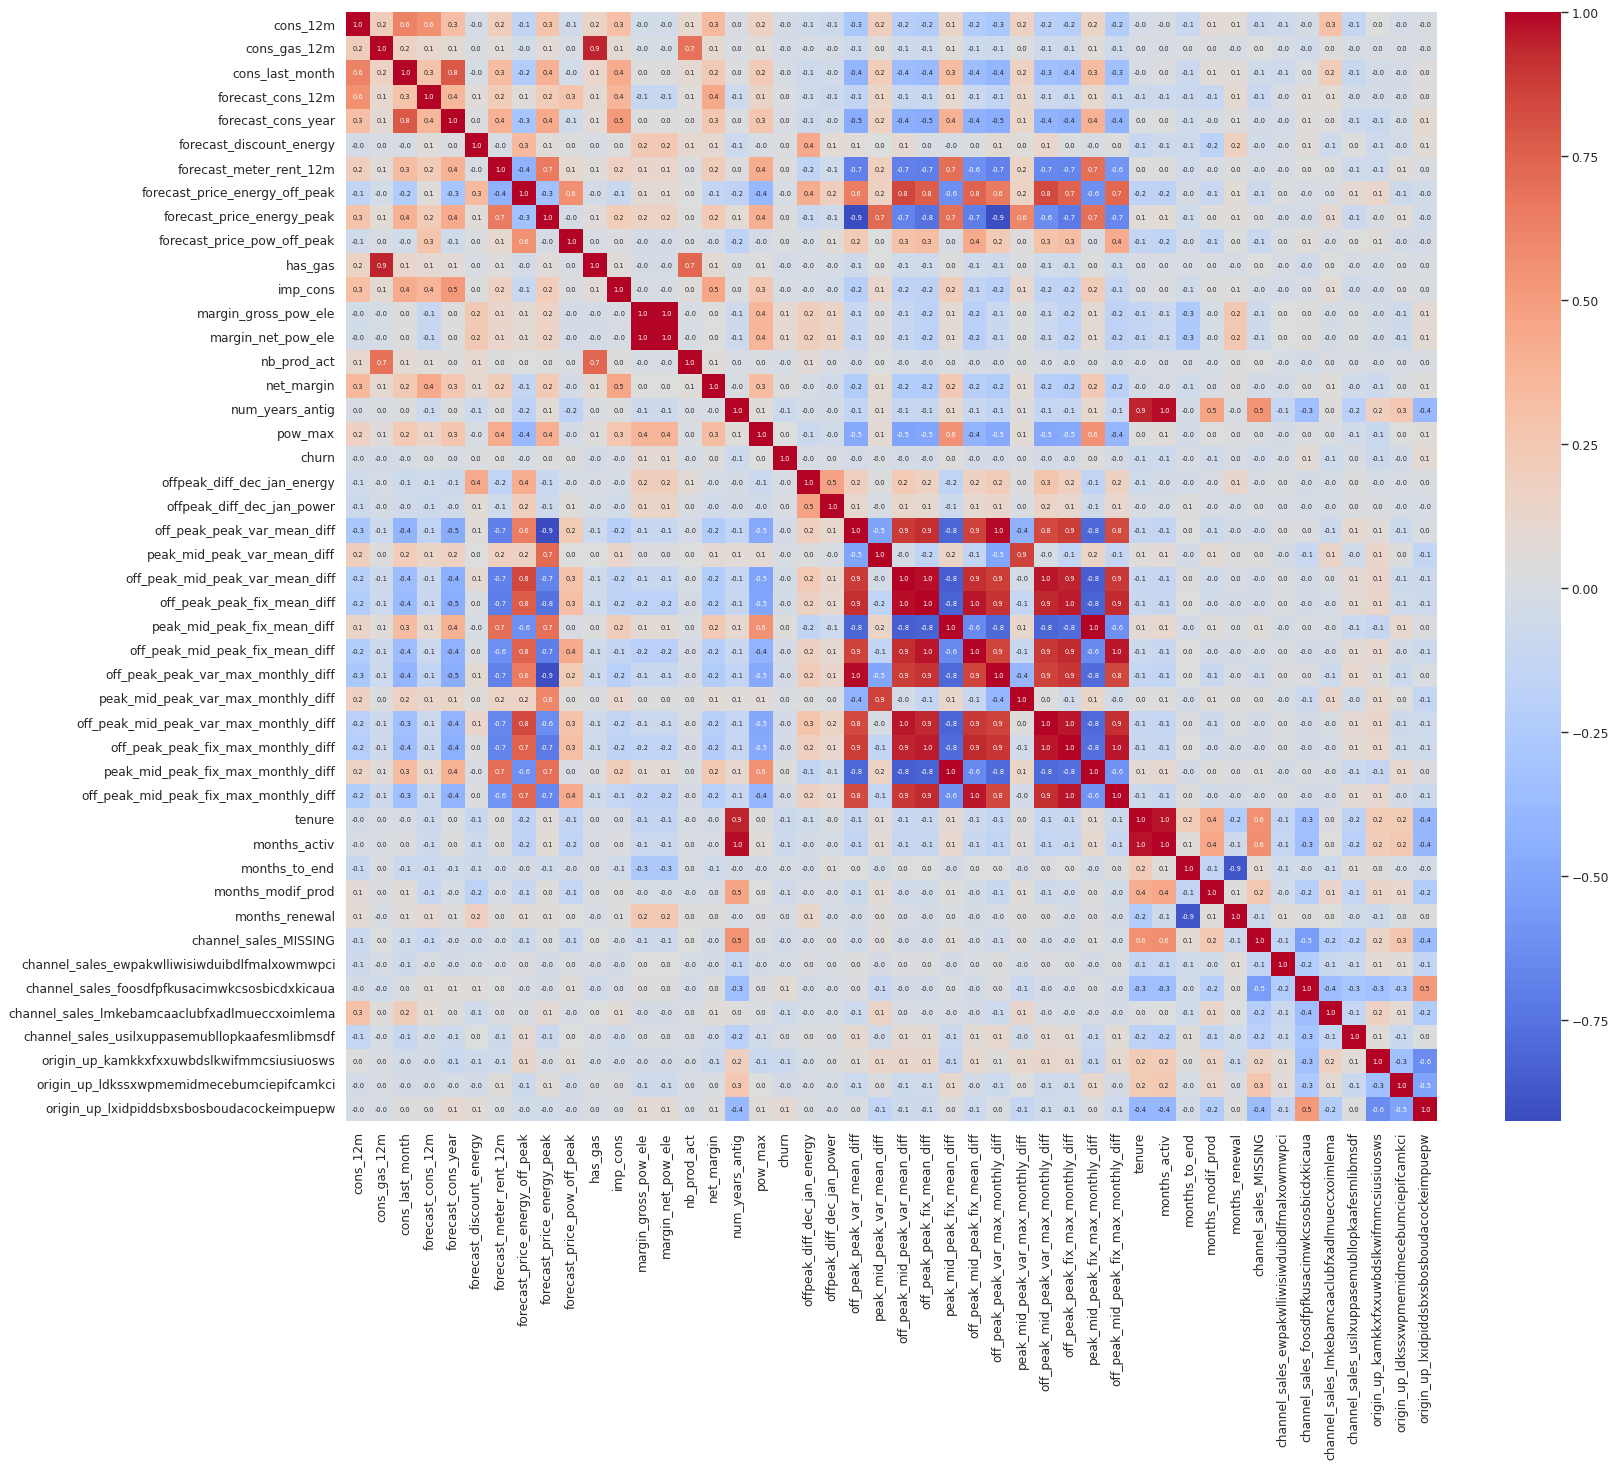

In [12]:
correlation = df.drop(columns=["id"]).corr()

plt.figure(figsize=(22, 18))
sns.heatmap(correlation, annot=True, annot_kws={"size": 6}, fmt=".1f", cmap="coolwarm")
plt.show()

In [13]:
# correlation with churn
correlation["churn"].drop("churn").sort_values(ascending=False).head(10)

margin_net_pow_ele                                0.095772
margin_gross_pow_ele                              0.095725
origin_up_lxidpiddsbxsbosboudacockeimpuepw        0.094131
channel_sales_foosdfpfkusacimwkcsosbicdxkicaua    0.075964
peak_mid_peak_fix_mean_diff                       0.045879
peak_mid_peak_fix_max_monthly_diff                0.045795
net_margin                                        0.041135
forecast_meter_rent_12m                           0.038964
pow_max                                           0.030362
forecast_price_energy_peak                        0.029070
Name: churn, dtype: float64

Drop two columns that are highly correlated with other features.

In [14]:
df = df.drop(columns=["num_years_antig", "forecast_cons_year"])

# save for the modelling step
df.to_csv("../data/data_for_modelling.csv", index=False)
df.shape

(14606, 45)